# Estimación de niveles de obesidad (UCI 544) — EDA, selección de variables, modelos y Optuna

**Integrantes y aportes** (completar; el enunciado pide indicar qué hizo cada uno):

- Integrante 1: ...
- Integrante 2: ...
- Integrante 3: ...
- Integrante 4: ...

**Uso de IA en el código** (completar con lo que realmente hicieron): el enunciado solo permite usar IA cuando se está atascado en algo específico y exige dejar el prompt como comentario. Si se usó, pegar aquí el prompt y a qué parte del código corresponde.

> `# PROMPT usado: ...`

---

## Cómo está armado este cuaderno

1. **EDA:** faltantes, duplicados, distribución de clases, variables "discretas" con decimales (efecto de SMOTE), outliers y evidencia de que la etiqueta se calcula con el IMC.
2. **Separación** en entrenamiento y prueba **antes** de cualquier ajuste. Escalado, codificación y selección de variables viven dentro de un `Pipeline` (así se ajustan solo con entrenamiento y también dentro de la validación cruzada).
3. **Dos escenarios**, porque la etiqueta se calcula a partir de `Weight` y `Height` (fuga de información):
   - **A:** con todas las variables.
   - **B:** sin `Weight` ni `Height` (el modelo debe aprender de los hábitos).
4. **Modelos:**
   - *Referencia (ya usados por los autores):* regresión logística, árbol de decisión, Naive Bayes, Random Forest, SVM y MLP.
   - *Propuestos (no aparecen en los estudios de los autores):* **XGBoost** y **KNN**, optimizados con **Optuna**.
5. **Comparación final** de todos los modelos en ambos escenarios.

**Qué usaron los autores (confirmar leyendo los artículos):** J48, Naive Bayes y regresión logística en De-La-Hoz-Correa et al. (2019); LMT, Random Forest, MLP y SVM, con selección de atributos, en Molina, De-La-Hoz y Mendoza (2021, *JATIT* 99(11)). Ese segundo estudio describe una muestra distinta (178 estudiantes), pero por prudencia se tratan esos métodos como ya usados.

In [ ]:
!pip install -q optuna xgboost

In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")

SEED = 42   # semilla fija para que los resultados sean reproducibles (el valor es arbitrario)

URL = "https://raw.githubusercontent.com/20232405-cloud/Estimaci-n-de-los-niveles-de-obesidad-basada-en-los-h-bitos-alimenticios-y-la-condici-n-f-sica/refs/heads/main/ObesityDataSet_raw_and_data_sinthetic.csv"

## 1. Carga de datos y definición de columnas

In [ ]:
df = pd.read_csv(URL)
df.columns = [c.strip() for c in df.columns]
print(df.shape)    # esperado: (2111, 17)
df.head()

(2111, 17)


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [ ]:
# Redondear las variables discretas afectadas por la interpolación de SMOTE
# de acuerdo a la regla estándar (si decimal >= 0.5 al superior, de lo contrario se mantiene)
columnas_discretas_smote = ["FCVC", "NCP", "CH2O", "FAF", "TUE"]

print("Valores antes del redondeo (ejemplo primeras filas):")
display(df[columnas_discretas_smote].head())

# Aplicamos el redondeo estándar y convertimos a tipo entero
for col in columnas_discretas_smote:
    df[col] = df[col].round().astype(int)

print("\nValores después del redondeo corregido:")
display(df[columnas_discretas_smote].head())


Valores antes del redondeo (ejemplo primeras filas):


,FCVC,NCP,CH2O,FAF,TUE
0,2.0,3.0,2.0,0.0,1.0
1,3.0,3.0,3.0,3.0,0.0
2,2.0,3.0,2.0,2.0,1.0
3,3.0,3.0,2.0,2.0,0.0
4,2.0,1.0,2.0,0.0,0.0



Valores después del redondeo corregido:


,FCVC,NCP,CH2O,FAF,TUE
0,2,3,2,0,1
1,3,3,3,3,0
2,2,3,2,2,1
3,3,3,2,2,0
4,2,1,2,0,0


In [ ]:
TARGET = "NObeyesdad"

# Orden natural de las clases (de menor a mayor peso). No se usa el orden alfabético.
ORDEN_CLASES = ["Insufficient_Weight", "Normal_Weight", "Overweight_Level_I", "Overweight_Level_II",
                "Obesity_Type_I", "Obesity_Type_II", "Obesity_Type_III"]

binarias  = ["Gender", "family_history_with_overweight", "FAVC", "SMOKE", "SCC"]   # dos categorías (texto)
ordinales = ["CAEC", "CALC"]                                                       # no < Sometimes < Frequently < Always
nominales = ["MTRANS"]                                                             # medio de transporte (sin orden)
numericas = ["Age", "Height", "Weight", "FCVC", "NCP", "CH2O", "FAF", "TUE"]

definidas = set(binarias + ordinales + nominales + numericas + [TARGET])
#Todas las columnas fueron asignadas del csv
print("En el CSV pero no en mis listas:", set(df.columns) - definidas)
# Todas las clolumnas son correctas sin errores ortograficos o inventados
print("En mis listas pero no en el CSV:", definidas - set(df.columns))
#Medidas de seguridad para no arrastrar errores al pipelines
assert definidas == set(df.columns), "Revisar los nombres de columnas"
assert set(df[TARGET].unique()) == set(ORDEN_CLASES), "Clases inesperadas en el objetivo"

En el CSV pero no en mis listas: set()
En mis listas pero no en el CSV: set()


## 2. Análisis exploratorio (EDA)

### 2.1 Variable objetivo

                     Cantidad  Porcentaje
NObeyesdad                               
Insufficient_Weight       272       12.88
Normal_Weight             287       13.60
Overweight_Level_I        290       13.74
Overweight_Level_II       290       13.74
Obesity_Type_I            351       16.63
Obesity_Type_II           297       14.07
Obesity_Type_III          324       15.35


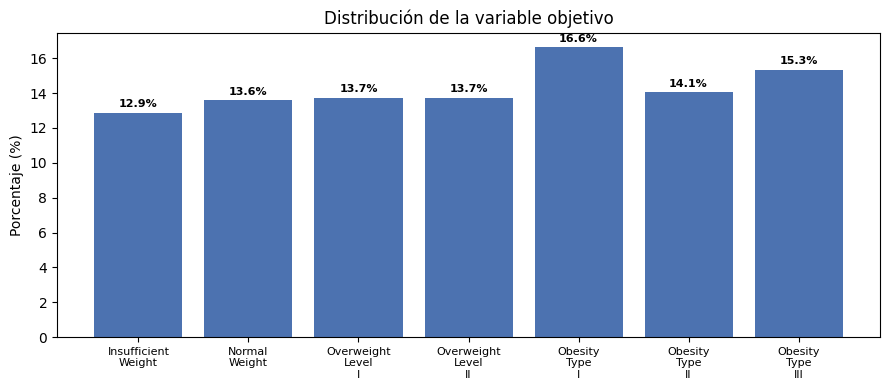

In [ ]:

#Ordenamos de menor a mayor con reindex
#Al codificar las etiquetas como números (0, 1, 2, 3, 4, 5, 6)
dist = df[TARGET].value_counts().reindex(ORDEN_CLASES)

#Calcular porcentaje
pct = dist / len(df) * 100
print(pd.DataFrame({"Cantidad": dist, "Porcentaje": pct.round(2)}))

#Grafica
plt.figure(figsize=(9, 4))
plt.bar(range(len(pct)), pct.values, color="#4c72b0")
plt.xticks(range(len(pct)), [c.replace("_", "\n") for c in pct.index], fontsize=8)
for i, v in enumerate(pct.values):
    plt.text(i, v + 0.3, f"{v:.1f}%", ha="center", fontsize=8, fontweight="bold")
plt.ylabel("Porcentaje (%)"); plt.title("Distribución de la variable objetivo")
plt.tight_layout(); plt.show()

**Interpretación (escribir con sus palabras):** ¿están balanceadas las clases? ¿por qué (recuerden que el 77% de los datos es sintético, generado con SMOTE para balancear)? ¿hace falta aplicar otra técnica de balanceo?

### 2.2 Faltantes y duplicados

In [ ]:
print("Valores nulos totales:", int(df.isna().sum().sum()))
n_dup = int(df.duplicated().sum())
print("Filas duplicadas:", n_dup)

# Decisión: se eliminan los duplicados exactos ANTES de separar los datos, porque una fila idéntica
# podría quedar en entrenamiento y en prueba a la vez e inflar las métricas.
if n_dup > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print("Nuevo tamaño:", df.shape)

Valores nulos totales: 0
Filas duplicadas: 24
Nuevo tamaño: (2087, 17)


### 2.3 Variables "discretas" con decimales

`FCVC`, `NCP`, `CH2O`, `FAF` y `TUE` son respuestas de encuesta con pocas opciones (por ejemplo "nunca / a veces / siempre"). Si aparecen valores no enteros, son producto de SMOTE (que interpola entre registros reales).

In [ ]:
# Verificación de decimales tras la aplicación del redondeo
discretas = ["FCVC", "NCP", "CH2O", "FAF", "TUE"]
tabla_dec = pd.DataFrame({
    "Valores únicos": [df[c].nunique() for c in discretas],
    "Filas con decimales": [int((df[c] != df[c].round()).sum()) for c in discretas],
    "Porcentaje con decimales": [round((df[c] != df[c].round()).mean() * 100, 1) for c in discretas],
}, index=discretas)

print("Verificación de decimales después de aplicar la corrección:")
display(tabla_dec)

Verificación de decimales después de aplicar la corrección:


,Valores únicos,Filas con decimales,Porcentaje con decimales
FCVC,3,0,0.0
NCP,4,0,0.0
CH2O,3,0,0.0
FAF,4,0,0.0
TUE,3,0,0.0


```markdown
**Decisión (Actualizada por recomendación del docente):** Se decidió **corregir** el problema de interpolación de SMOTE redondeando los valores de las variables discretas (`FCVC`, `NCP`, `CH2O`, `FAF`, `TUE`) a sus enteros más cercanos (aplicando la regla de si el decimal es $\ge 0.5$ se redondea al superior). Esto elimina los valores decimales físicamente imposibles en variables de encuesta manteniendo la escala original.

**Interpretación (escribir con sus palabras):** ¿Por qué surgieron decimales originalmente en estas variables? (Respuesta: Debido a que SMOTE genera datos artificiales interpolando linealmente entre registros reales de vecinos cercanos, lo que convierte variables originalmente enteras en variables continuas).
```

,Variable,Límite inferior,Límite superior,Outliers,Porcentaje
0,CH2O,2.00,2.00,980,46.96
1,NCP,3.00,3.00,621,29.76
2,Age,10.79,35.13,167,8.00
3,Height,1.42,1.98,1,0.05
4,Weight,2.98,171.04,1,0.05
5,FCVC,0.50,4.50,0,0.00
6,FAF,-3.00,5.00,0,0.00
7,TUE,-1.50,2.50,0,0.00


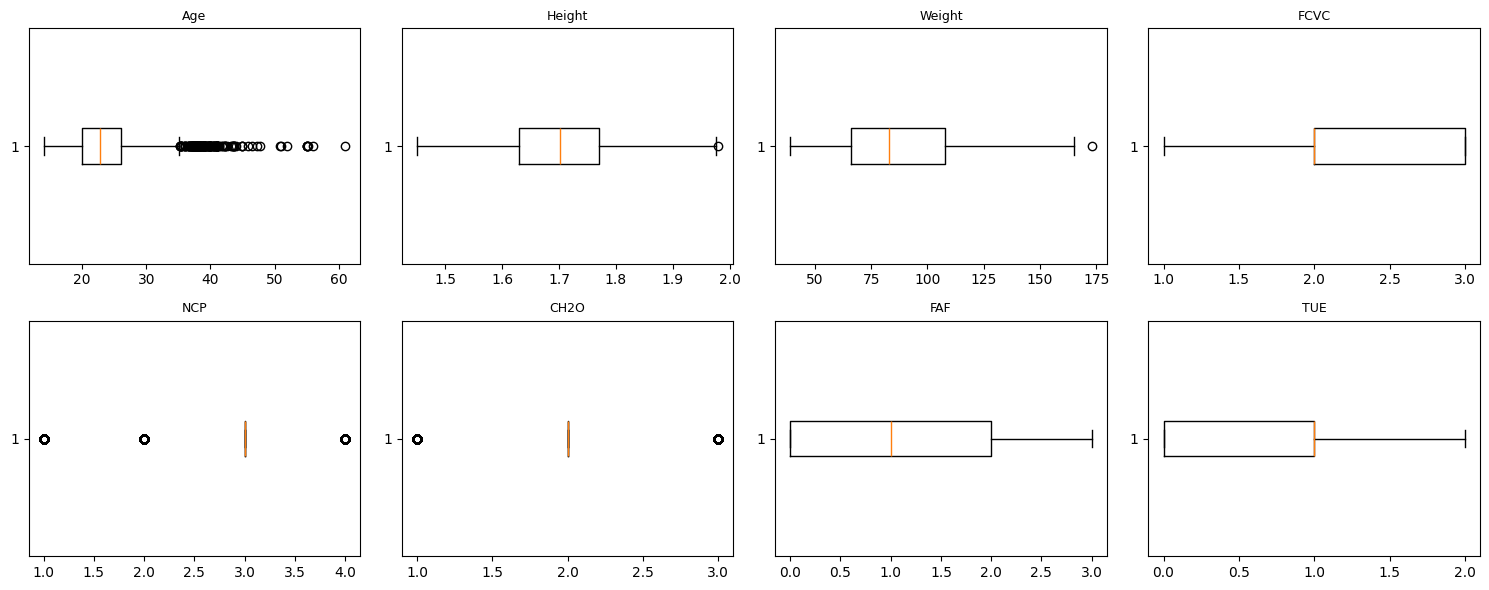

In [ ]:
def resumen_outliers_iqr(data, variables):
    filas = []
    for v in variables:
        q1, q3 = data[v].quantile(0.25), data[v].quantile(0.75)
        iqr = q3 - q1
        inf, sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n = int(((data[v] < inf) | (data[v] > sup)).sum())
        filas.append({"Variable": v, "Límite inferior": round(inf, 2), "Límite superior": round(sup, 2),
                      "Outliers": n, "Porcentaje": round(n / len(data) * 100, 2)})
    return pd.DataFrame(filas).sort_values("Outliers", ascending=False).reset_index(drop=True)

display(resumen_outliers_iqr(df, numericas))

fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, v in zip(axes.ravel(), numericas):
    ax.boxplot(df[v], vert=False); ax.set_title(v, fontsize=9)
plt.tight_layout(); plt.show()

### Detección Alternativa de Outliers usando Z-score

Vamos a calcular la cantidad de outliers utilizando el método estándar de Z-score 0.27% más extremo de la población (la suma de las colas muy lejanas a la izquierda y a la derecha). (considerando outlier a cualquier observación con $|Z| > 3$) para contrastar los resultados con el método IQR anterior.

In [ ]:
from scipy import stats

def resumen_outliers_zscore(data, variables, umbral=3):
    filas = []
    for v in variables:
        # Calculamos el Z-score para la variable
        z_scores = np.abs(stats.zscore(data[v]))
        n = int((z_scores > umbral).sum())
        filas.append({
            "Variable": v,
            "Outliers (Z > 3)": n,
            "Porcentaje (Z)": round(n / len(data) * 100, 2)
        })
    return pd.DataFrame(filas).sort_values("Outliers (Z > 3)", ascending=False).reset_index(drop=True)

# Comparación de ambos métodos
tabla_iqr = resumen_outliers_iqr(df, numericas)[["Variable", "Outliers", "Porcentaje"]].rename(
    columns={"Outliers": "Outliers (IQR)", "Porcentaje": "Porcentaje (IQR)"}
)
tabla_z = resumen_outliers_zscore(df, numericas)

comparativa_outliers = pd.merge(tabla_iqr, tabla_z, on="Variable")
display(comparativa_outliers)

,Variable,Outliers (IQR),Porcentaje (IQR),Outliers (Z > 3),Porcentaje (Z)
0,CH2O,980,46.96,0,0.00
1,NCP,621,29.76,0,0.00
2,Age,167,8.00,23,1.10
3,Height,1,0.05,0,0.00
4,Weight,1,0.05,1,0.05
5,FCVC,0,0.00,0,0.00
6,FAF,0,0.00,0,0.00
7,TUE,0,0.00,0,0.00


**Interpretación (escribir con sus palabras):** ¿qué variables tienen outliers y qué decisión toman?

### 2.5 Correlación entre variables numéricas

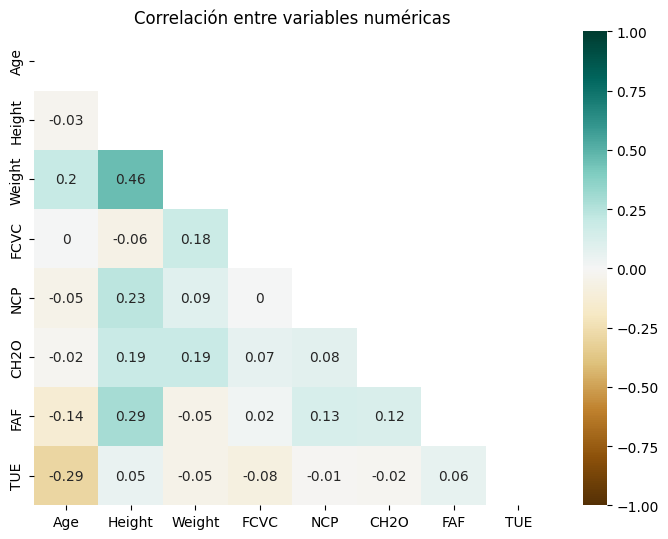

In [ ]:
corr_total = df[numericas].corr()
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr_total.round(2), mask=np.triu(np.ones_like(corr_total, dtype=bool)),
            cmap="BrBG", vmin=-1, vmax=1, annot=True)
plt.title("Correlación entre variables numéricas"); plt.tight_layout(); plt.show()

### 2.6 Evidencia de fuga de información: la etiqueta sale del IMC

Según el paper del dataset, la clase se calculó con el IMC = peso / altura² y los umbrales de la OMS. Si es así, el IMC (calculado a partir de `Weight` y `Height`) debería separar casi perfectamente las clases.

,min,mean,max
NObeyesdad,,,
Insufficient_Weight,13.0,17.4,19.1
Normal_Weight,18.5,22.0,24.9
Overweight_Level_I,22.8,26.0,28.8
Overweight_Level_II,25.7,28.2,30.4
Obesity_Type_I,29.9,32.3,35.2
Obesity_Type_II,34.0,36.7,39.8
Obesity_Type_III,36.8,42.3,50.8


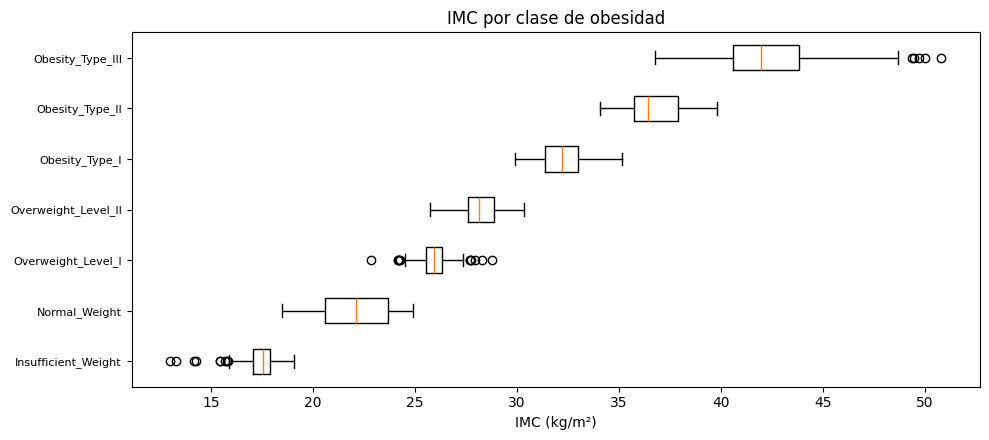

In [ ]:
df_imc = df.copy()
df_imc["IMC"] = df_imc["Weight"] / df_imc["Height"] ** 2

resumen_imc = df_imc.groupby(TARGET)["IMC"].agg(["min", "mean", "max"]).reindex(ORDEN_CLASES).round(1)
display(resumen_imc)

plt.figure(figsize=(10, 4.5))
plt.boxplot([df_imc.loc[df_imc[TARGET] == c, "IMC"] for c in ORDEN_CLASES], vert=False)
plt.yticks(range(1, 8), ORDEN_CLASES, fontsize=8)
plt.xlabel("IMC (kg/m²)"); plt.title("IMC por clase de obesidad")
plt.tight_layout(); plt.show()

**Interpretación (escribir con sus palabras):** ¿se solapan las clases en el IMC? ¿qué implica para los modelos que reciben `Weight` y `Height`? (Esta es la razón de los dos escenarios A y B.)

## 3. Separación en entrenamiento y prueba

Se hace **antes** de cualquier ajuste, con `stratify` para mantener la proporción de clases. La validación se hace con **validación cruzada sobre el entrenamiento**; el conjunto de prueba se usa **una sola vez al final**. El objetivo se codifica con el **orden natural** de las clases (no alfabético).

In [ ]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score

X = df.drop(columns=[TARGET])
assert TARGET not in X.columns          # el objetivo NO puede estar en X

mapa = {c: i for i, c in enumerate(ORDEN_CLASES)}
y = df[TARGET].map(mapa).values
CLASES = ORDEN_CLASES
#tanto el conjunto de entrenamiento como el de prueba mantengan exactamente la misma proporción de clases de obesidad que el dataset original.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)

#Hiperparametros y validacion cruzada evitar  "memorizarlos" (overfitting).
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

Entrenamiento: (1669, 16) | Prueba: (418, 16)


In [ ]:
# Prueba de la fuga: un árbol pequeño que recibe SOLO el IMC (validación cruzada en entrenamiento)
#95% de accuracy (0.950) significa que de cada 100 registros evaluados,
# el árbol de decisión clasificó correctamente el nivel de obesidad de 95 personas.
from sklearn.tree import DecisionTreeClassifier

imc_train = (X_train["Weight"] / X_train["Height"] ** 2).to_frame("IMC")
acc_imc = cross_val_score(DecisionTreeClassifier(max_depth=4, random_state=SEED), imc_train, y_train,
                          cv=cv5, scoring="accuracy")
print(f"Accuracy de un árbol (profundidad 4) usando solo el IMC: {acc_imc.mean():.3f}")

Accuracy de un árbol (profundidad 4) usando solo el IMC: 0.950


**Interpretación (escribir con sus palabras):** ¿qué dice ese número sobre lo que "aprende" un modelo que ve peso y altura?

## 4. Pipeline, selección de variables y utilidades

- **Codificación:** variables binarias → 0/1; `CAEC` y `CALC` → ordinal (no < Sometimes < Frequently < Always); `MTRANS` → one-hot; numéricas → estandarizadas.
- **Selección de variables (solo con entrenamiento):** (1) filtro por correlación |r| > 0.90 entre numéricas; (2) importancia con Random Forest, aplicada dentro del `Pipeline` con `SelectFromModel` para que se recalcule en cada fold. Se comparan tres configuraciones (sin selección, conservadora y agresiva) con validación cruzada y se elige la mejor.
- **Balanceo:** no se aplica, porque las clases ya están casi equilibradas.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.feature_selection import SelectFromModel
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score, confusion_matrix, classification_report

ORD_CATS = [["no", "Sometimes", "Frequently", "Always"]] * len(ordinales)

def construir_cfg(excluir=()):
    return {"num": [c for c in numericas if c not in excluir]}

def filtro_correlacion(num, umbral=0.90):
    corr = X_train[num].corr().abs()
    sup = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    return [c for c in sup.columns if (sup[c] > umbral).any()]

def crear_preprocesador(cfg):
    return ColumnTransformer([
        ("num", StandardScaler(), cfg["num"]),
        ("bin", OneHotEncoder(drop="if_binary", sparse_output=False), binarias),
        ("ord", Pipeline([("o", OrdinalEncoder(categories=ORD_CATS, handle_unknown="use_encoded_value", unknown_value=-1)),
                          ("s", StandardScaler())]), ordinales),
        ("nom", OneHotEncoder(handle_unknown="ignore", sparse_output=False), nominales),
    ])

def crear_pipeline(clf, cfg, seleccion):
    """seleccion: None (sin selección) o el umbral de SelectFromModel, p. ej. 'median' o '0.5*median'."""
    pasos = [("prep", crear_preprocesador(cfg))]
    if seleccion:
        pasos.append(("sel", SelectFromModel(
            RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1), threshold=seleccion)))
    pasos.append(("clf", clf))
    return Pipeline(pasos)

def cv_f1(pipe, cv=cv5):
    r = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
    return r.mean(), r.std()

resultados = []       # una fila por modelo y escenario (tabla final)
predicciones = {}     # para matrices de confusión

def registrar(escenario, nombre, origen, pipe):
    """Ajusta con TODO el entrenamiento y evalúa UNA vez en prueba."""
    f1_cv, _ = cv_f1(pipe)
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    errores = pred != y_test
    adyacentes = (np.abs(pred.astype(int) - y_test.astype(int)) == 1) & errores
    fila = {
        "Escenario": escenario, "Modelo": nombre, "Origen": origen,
        "F1 macro (CV)": round(f1_cv, 4),
        "Accuracy (prueba)": round(accuracy_score(y_test, pred), 4),
        "F1 macro (prueba)": round(f1_score(y_test, pred, average="macro"), 4),
        "Recall macro (prueba)": round(recall_score(y_test, pred, average="macro"), 4),
        "% errores a clase vecina": round(adyacentes.sum() / max(errores.sum(), 1) * 100, 1),
    }
    predicciones[(escenario, nombre)] = pred
    resultados.append(fila)
    return pipe

In [ ]:
!pip install -q boruta

In [ ]:
from boruta import BorutaPy
from sklearn.ensemble import RandomForestClassifier
import pandas as pd
import numpy as np

# 1. Preprocesar los datos de entrenamiento para alimentar a Boruta (Boruta requiere matrices NumPy numéricas)
cfg_boruta = construir_cfg(excluir=[])
prep_boruta = crear_preprocesador(cfg_boruta)
X_train_prep = prep_boruta.fit_transform(X_train)
nombres_columnas = [col.split("__", 1)[1] for col in prep_boruta.get_feature_names_out()]

# 2. Inicializar el clasificador base (Random Forest) y el selector Boruta
rf_base = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=SEED, n_jobs=-1)
boruta_selector = BorutaPy(rf_base, n_estimators='auto', random_state=SEED, verbose=0, max_iter=100)

# Ajustar Boruta
boruta_selector.fit(X_train_prep, y_train)

# 3. Analizar variables aceptadas y rechazadas
variables_seleccionadas = [nombres_columnas[i] for i in range(len(nombres_columnas)) if boruta_selector.support_[i]]
variables_dudosas = [nombres_columnas[i] for i in range(len(nombres_columnas)) if boruta_selector.support_weak_[i]]

print("=== RESULTADOS DE SELECCIÓN CON BORUTA ===")
print(f"Variables confirmadas ({len(variables_seleccionadas)}): {variables_seleccionadas}")
print(f"Variables dudosas ({len(variables_dudosas)}): {variables_dudosas}")


=== RESULTADOS DE SELECCIÓN CON BORUTA ===
Variables confirmadas (15): ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE', 'Gender_Male', 'family_history_with_overweight_yes', 'FAVC_yes', 'CAEC', 'CALC', 'MTRANS_Automobile', 'MTRANS_Public_Transportation']
Variables dudosas (0): []


In [ ]:
# 4. Calcular el rendimiento del modelo (F1-macro) utilizando únicamente las variables seleccionadas por Boruta
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import FunctionTransformer

# Crear un transformador para filtrar solo las columnas aprobadas por Boruta
def filtrar_columnas_boruta(X):
    # Obtenemos los índices de las columnas seleccionadas en el preprocesamiento
    indices = [i for i, sup in enumerate(boruta_selector.support_) if sup]
    return X[:, indices]

pipeline_boruta = Pipeline([
    ("prep", crear_preprocesador(cfg_boruta)),
    ("boruta_filter", FunctionTransformer(filtrar_columnas_boruta)),
    ("clf", RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1))
])

f1_boruta_cv, _ = cv_f1(pipeline_boruta)
print(f"F1 macro obtenido con selección de variables por Boruta: {f1_boruta_cv:.4f}")

F1 macro obtenido con selección de variables por Boruta: 0.9295


### 4.1 Análisis y Reporte de Preprocesamiento y Selección de Atributos

Este bloque de código ejecuta la simulación del preprocesamiento y la selección de variables utilizando los datos reales de entrenamiento. Nos ayuda a documentar de forma visual qué variables aportan mayor peso antes del entrenamiento de los modelos definitivos.

=== ESTADÍSTICAS DEL PREPROCESAMIENTO Y VARIABLES ===
Total de variables de entrada originales: 16
Total de variables tras preprocesamiento (One-Hot y Ordinales): 20
Mediana de importancia calculada: 0.0333
Umbral de selección conservador (0.5 * Mediana): 0.0167



,Variable Procesada,Importancia (Gini),Pasa Selección (Conservadora),Pasa Selección (Agresiva)
0,Weight,0.3028,True,True
1,Age,0.0985,True,True
2,Height,0.0981,True,True
3,FCVC,0.0886,True,True
4,NCP,0.0565,True,True
5,Gender_Male,0.0544,True,True
6,TUE,0.0499,True,True
7,FAF,0.0491,True,True
8,CH2O,0.0464,True,True
9,family_history_with_overweight_yes,0.0343,True,True


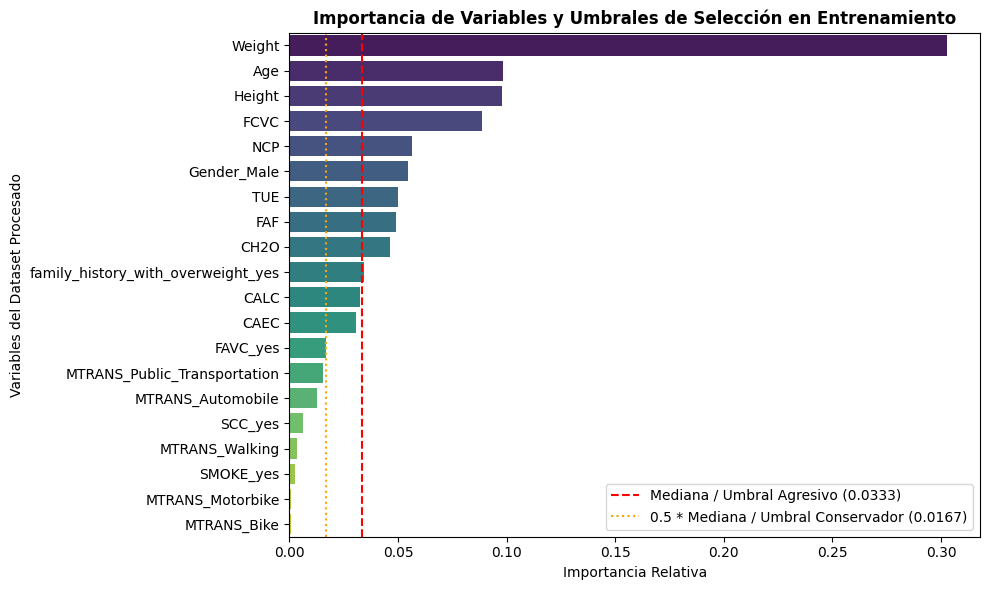

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Configuramos el escenario por defecto (con todas las variables)
cfg_analisis = construir_cfg(excluir=[])

# 2. Inicializamos y ajustamos el preprocesador sobre el conjunto de entrenamiento
preprocesador = crear_preprocesador(cfg_analisis)
X_train_procesado = preprocesador.fit_transform(X_train)

# Obtener los nombres correctos de las columnas tras las codificaciones (One-Hot, Ordinal, StandardScaler)
nombres_columnas = [col.split("__", 1)[1] for col in preprocesador.get_feature_names_out()]

# 3. Entrenamos un estimador de Random Forest interno sobre los datos procesados para evaluar importancias
rf_analizador = RandomForestClassifier(n_estimators=150, random_state=SEED, n_jobs=-1)
rf_analizador.fit(X_train_procesado, y_train)
importancias = rf_analizador.feature_importances_

# Creamos un dataframe consolidado con los resultados
analisis_variables = pd.DataFrame({
    'Variable Procesada': nombres_columnas,
    'Importancia (Gini)': importancias
}).sort_values(by='Importancia (Gini)', ascending=False).reset_index(drop=True)

# Umbrales aplicados por SelectFromModel
mediana = analisis_variables['Importancia (Gini)'].median()
umbral_conservador = 0.5 * mediana

analisis_variables['Pasa Selección (Conservadora)'] = analisis_variables['Importancia (Gini)'] >= umbral_conservador
analisis_variables['Pasa Selección (Agresiva)'] = analisis_variables['Importancia (Gini)'] >= mediana

# Imprimir métricas de la sección
print("=== ESTADÍSTICAS DEL PREPROCESAMIENTO Y VARIABLES ===")
print(f"Total de variables de entrada originales: {X_train.shape[1]}")
print(f"Total de variables tras preprocesamiento (One-Hot y Ordinales): {len(nombres_columnas)}")
print(f"Mediana de importancia calculada: {mediana:.4f}")
print(f"Umbral de selección conservador (0.5 * Mediana): {umbral_conservador:.4f}\n")
#es exactamente la mitad de la mediana 0.0333 \times 0.5 = 0.0167

# Mostrar tabla del estado de las variables
display(analisis_variables.style.background_gradient(cmap='Blues', subset=['Importancia (Gini)'])
                         .format({'Importancia (Gini)': '{:.4f}'}))

# Graficar importancia
plt.figure(figsize=(10, 6))
sns.barplot(data=analisis_variables, x='Importancia (Gini)', y='Variable Procesada', palette='viridis')
plt.axvline(x=mediana, color='red', linestyle='--', label=f'Mediana / Umbral Agresivo ({mediana:.4f})')
plt.axvline(x=umbral_conservador, color='orange', linestyle=':', label=f'0.5 * Mediana / Umbral Conservador ({umbral_conservador:.4f})')
plt.title('Importancia de Variables y Umbrales de Selección en Entrenamiento', fontsize=12, fontweight='bold')
plt.xlabel('Importancia Relativa')
plt.ylabel('Variables del Dataset Procesado')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 5. Modelos y Optuna

Las funciones de abajo se ejecutan **una vez por escenario** (sección 6).

- **Referencia (métodos de los autores):** regresión logística, árbol de decisión (criterio de entropía, parecido a J48), Naive Bayes, Random Forest, SVM y MLP.
- **Propuestos:** **XGBoost** (boosting de árboles: construye árboles en secuencia corrigiendo los errores del anterior; suele rendir muy bien en datos tabulares) y **KNN** (clasifica por cercanía a los vecinos; es un método distinto, basado en distancias). Justificar en el reporte.
- **Optuna:** busca la combinación de hiperparámetros que maximiza el F1 macro en validación cruzada (3 folds) sobre el entrenamiento. El conjunto de prueba no interviene.

> `N_TRIALS = 30` tarda unos minutos en Colab. Pueden bajarlo para probar y subirlo para la versión final.

In [ ]:
import optuna
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

optuna.logging.set_verbosity(optuna.logging.WARNING)
N_TRIALS = 30

def optimizar(sugerir, construir, n_trials=N_TRIALS):
    def objetivo(trial):
        pipe = construir(sugerir(trial))
        return cross_val_score(pipe, X_train, y_train, cv=cv3, scoring="f1_macro", n_jobs=-1).mean()
    estudio = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
    estudio.optimize(objetivo, n_trials=n_trials)
    return estudio

def graficar_optuna(estudio, titulo):
    vals = estudio.trials_dataframe()["value"]
    plt.figure(figsize=(6, 3.5))
    plt.plot(vals, "o", alpha=0.5, label="cada prueba")
    plt.plot(vals.cummax(), "-", label="mejor hasta el momento")
    plt.xlabel("Prueba"); plt.ylabel("F1 macro (CV)"); plt.title(titulo); plt.legend()
    plt.tight_layout(); plt.show()

def sugerir_knn(trial):
    return {"n_neighbors": trial.suggest_int("n_neighbors", 3, 51),
            "weights": trial.suggest_categorical("weights", ["uniform", "distance"]),
            "p": trial.suggest_int("p", 1, 2)}                      # 1 = Manhattan, 2 = Euclídea

def sugerir_xgb(trial):
    return {"n_estimators": trial.suggest_int("n_estimators", 100, 500, step=50),
            "max_depth": trial.suggest_int("max_depth", 2, 10),
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
            "subsample": trial.suggest_float("subsample", 0.5, 1.0),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
            "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
            "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True)}

def nuevo_xgb(**params):
    return XGBClassifier(random_state=SEED, n_jobs=1, eval_metric="mlogloss", verbosity=0, **params)

In [ ]:
def ejecutar_escenario(nombre, excluir):
    print("=" * 70); print("ESCENARIO", nombre); print("=" * 70)

    # ---------- selección de variables (solo entrenamiento)
    cfg = construir_cfg(excluir)
    eliminadas = filtro_correlacion(cfg["num"])
    cfg["num"] = [c for c in cfg["num"] if c not in eliminadas]
    print("Numéricas usadas:", cfg["num"])
    print("Eliminadas por correlación > 0.90:", eliminadas if eliminadas else "ninguna")

    prep = crear_preprocesador(cfg).fit(X_train)
    nombres = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]
    rf_doc = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1).fit(prep.transform(X_train), y_train)
    imp = pd.Series(rf_doc.feature_importances_, index=nombres).sort_values()
    imp.tail(12).plot(kind="barh", figsize=(7, 4.5), title=f"Importancia de variables (RF, solo entrenamiento)\n{nombre}")
    plt.tight_layout(); plt.show()

    # ---------- ¿conviene usar SelectFromModel? (se prueban tres configuraciones con validación cruzada)
    rf = lambda: RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)
    opciones = {"Sin selección": None,
                "Conservadora (umbral 0.5 x mediana)": "0.5*median",
                "Agresiva (umbral mediana)": "median"}
    filas_sel = []
    for etiqueta, umbral in opciones.items():
        f1_sel, desv_sel = cv_f1(crear_pipeline(rf(), cfg, umbral))
        n_cols = crear_pipeline(RandomForestClassifier(n_estimators=50, random_state=SEED), cfg, umbral).fit(X_train, y_train)
        n_cols = n_cols[:-1].transform(X_train).shape[1]
        filas_sel.append({"Configuración": etiqueta, "Columnas": n_cols,
                          "F1 macro (CV)": round(f1_sel, 4), "Desv.": round(desv_sel, 4)})
    tabla_sel = pd.DataFrame(filas_sel)
    display(tabla_sel)
    elegida = tabla_sel.loc[tabla_sel["F1 macro (CV)"].idxmax(), "Configuración"]
    sel_elegida = opciones[elegida]
    print("Configuración elegida:", elegida)

    mk = lambda clf: crear_pipeline(clf, cfg, sel_elegida)

    # ---------- referencia: métodos de los autores
    registrar(nombre, "Regresión logística", "Autores", mk(LogisticRegression(max_iter=3000, random_state=SEED)))
    registrar(nombre, "Árbol de decisión", "Autores", mk(DecisionTreeClassifier(criterion="entropy", min_samples_leaf=2, random_state=SEED)))
    registrar(nombre, "Naive Bayes", "Autores", mk(GaussianNB()))
    registrar(nombre, "Random Forest", "Autores", mk(RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)))
    registrar(nombre, "SVM", "Autores", mk(SVC(random_state=SEED)))
    registrar(nombre, "MLP", "Autores", mk(MLPClassifier(hidden_layer_sizes=(64,), max_iter=500, early_stopping=True, random_state=SEED)))

    # ---------- propuestos sin ajustar
    registrar(nombre, "KNN (sin ajustar)", "Propuesto", mk(KNeighborsClassifier()))
    registrar(nombre, "XGBoost (sin ajustar)", "Propuesto", mk(nuevo_xgb()))

    # ---------- propuestos con Optuna, oprtuna unicamente sobre el ganador de los 3 seleccionados
    est_knn = optimizar(sugerir_knn, lambda p: mk(KNeighborsClassifier(**p)))
    print("KNN  | mejor F1 macro (CV):", round(est_knn.best_value, 4), "|", est_knn.best_params)
    graficar_optuna(est_knn, f"Optuna - KNN ({nombre})")
    registrar(nombre, "KNN (Optuna)", "Propuesto", mk(KNeighborsClassifier(**est_knn.best_params)))

    est_xgb = optimizar(sugerir_xgb, lambda p: mk(nuevo_xgb(**p)))
    print("XGB  | mejor F1 macro (CV):", round(est_xgb.best_value, 4), "|", est_xgb.best_params)
    graficar_optuna(est_xgb, f"Optuna - XGBoost ({nombre})")
    try:
        imp_hp = optuna.importance.get_param_importances(est_xgb)
        print("Importancia de hiperparámetros (XGBoost):", {k: round(v, 3) for k, v in imp_hp.items()})
    except Exception as e:
        print("No se pudo calcular la importancia de hiperparámetros:", e)
    registrar(nombre, "XGBoost (Optuna)", "Propuesto", mk(nuevo_xgb(**est_xgb.best_params)))

    return {"knn": est_knn, "xgb": est_xgb}

## 6. Ejecución de los escenarios

### Escenario A: con todas las variables (incluye `Weight` y `Height`)

ESCENARIO A: con Weight y Height
Numéricas usadas: ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']
Eliminadas por correlación > 0.90: ninguna


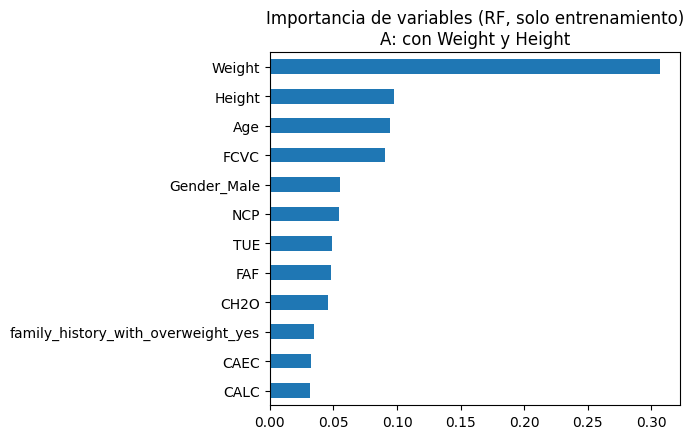

,Configuración,Columnas,F1 macro (CV),Desv.
0,Sin selección,20,0.9379,0.0055
1,Conservadora (umbral 0.5 x mediana),13,0.9390,0.0056
2,Agresiva (umbral mediana),10,0.9332,0.0140


Configuración elegida: Conservadora (umbral 0.5 x mediana)
KNN  | mejor F1 macro (CV): 0.8651 | {'n_neighbors': 3, 'weights': 'distance', 'p': 1}


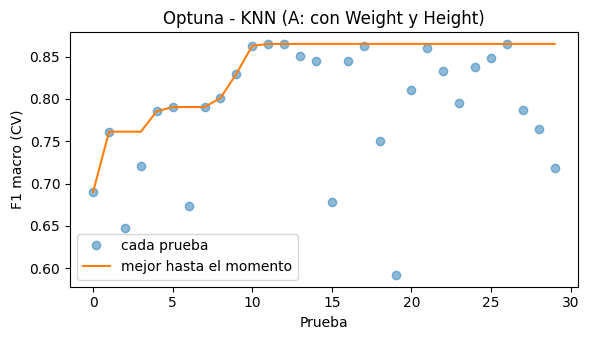

XGB  | mejor F1 macro (CV): 0.956 | {'n_estimators': 150, 'max_depth': 6, 'learning_rate': 0.25766306785002085, 'subsample': 0.6952403357814902, 'colsample_bytree': 0.7340842252033922, 'min_child_weight': 2, 'reg_lambda': 0.001958043789010253}


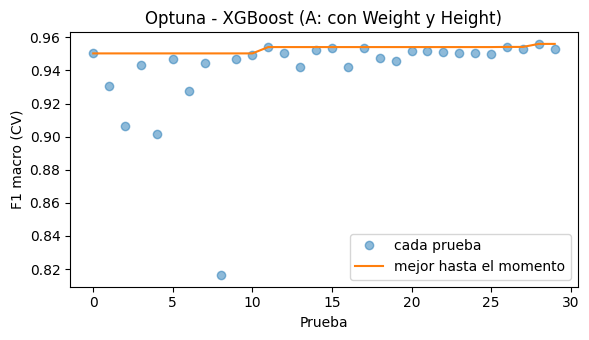

Importancia de hiperparámetros (XGBoost): {'min_child_weight': 0.3, 'reg_lambda': 0.279, 'learning_rate': 0.175, 'max_depth': 0.122, 'n_estimators': 0.064, 'colsample_bytree': 0.032, 'subsample': 0.028}


,Escenario,Modelo,Origen,F1 macro (CV),Accuracy (prueba),F1 macro (prueba),Recall macro (prueba),% errores a clase vecina
0,A: con Weight y Height,Regresión logística,Autores,0.8650,0.8660,0.8601,0.8632,94.6
1,A: con Weight y Height,Árbol de decisión,Autores,0.9205,0.9569,0.9563,0.9564,88.9
2,A: con Weight y Height,Naive Bayes,Autores,0.5864,0.6220,0.6002,0.6195,63.3
3,A: con Weight y Height,Random Forest,Autores,0.9415,0.9498,0.9483,0.9472,90.5
4,A: con Weight y Height,SVM,Autores,0.8943,0.9091,0.9058,0.9070,76.3
5,A: con Weight y Height,MLP,Autores,0.6391,0.8636,0.8582,0.8602,93.0
6,A: con Weight y Height,KNN (sin ajustar),Propuesto,0.7937,0.8278,0.8112,0.8237,62.5
7,A: con Weight y Height,XGBoost (sin ajustar),Propuesto,0.9608,0.9569,0.9562,0.9552,100.0
8,A: con Weight y Height,KNN (Optuna),Propuesto,0.8610,0.8732,0.8645,0.8675,64.2
9,A: con Weight y Height,XGBoost (Optuna),Propuesto,0.9520,0.9569,0.9557,0.9552,88.9


In [ ]:
ESC_A = "A: con Weight y Height"
estudios_A = ejecutar_escenario(ESC_A, excluir=[])
display(pd.DataFrame([r for r in resultados if r["Escenario"] == ESC_A]))

**Interpretación (escribir con sus palabras):** ¿qué tan altas son las métricas y por qué (fuga del IMC + datos sintéticos)? ¿mejoran los modelos propuestos algo que ya está cerca del techo?

### Escenario B: sin `Weight` ni `Height` (solo hábitos y datos demográficos)

ESCENARIO B: sin Weight ni Height
Numéricas usadas: ['Age', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']
Eliminadas por correlación > 0.90: ninguna


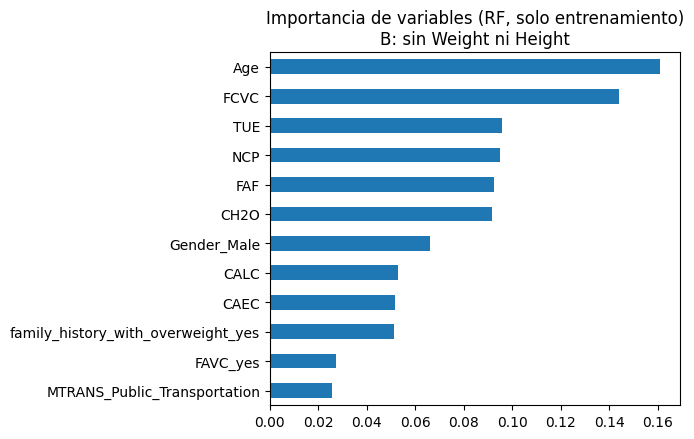

,Configuración,Columnas,F1 macro (CV),Desv.
0,Sin selección,18,0.8503,0.0231
1,Conservadora (umbral 0.5 x mediana),12,0.8449,0.0255
2,Agresiva (umbral mediana),9,0.8050,0.0190


Configuración elegida: Sin selección
KNN  | mejor F1 macro (CV): 0.774 | {'n_neighbors': 3, 'weights': 'distance', 'p': 1}


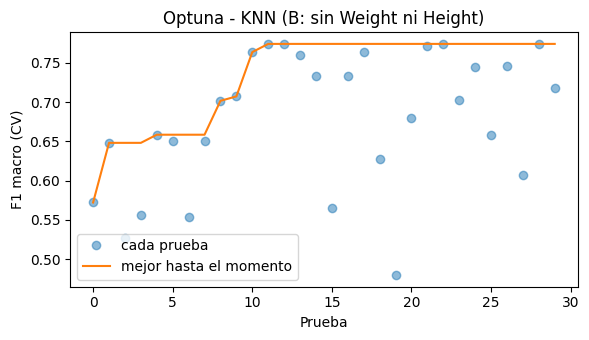

XGB  | mejor F1 macro (CV): 0.8316 | {'n_estimators': 100, 'max_depth': 10, 'learning_rate': 0.10465983234557358, 'subsample': 0.7613280428747656, 'colsample_bytree': 0.6892137941791393, 'min_child_weight': 1, 'reg_lambda': 0.7926564326946378}


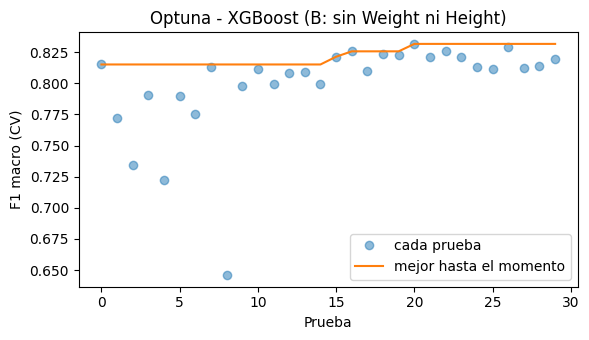

Importancia de hiperparámetros (XGBoost): {'min_child_weight': 0.259, 'reg_lambda': 0.227, 'learning_rate': 0.186, 'colsample_bytree': 0.105, 'subsample': 0.081, 'n_estimators': 0.08, 'max_depth': 0.063}


,Escenario,Modelo,Origen,F1 macro (CV),Accuracy (prueba),F1 macro (prueba),Recall macro (prueba),% errores a clase vecina
0,B: sin Weight ni Height,Regresión logística,Autores,0.5452,0.5789,0.5521,0.5679,48.3
1,B: sin Weight ni Height,Árbol de decisión,Autores,0.7199,0.7177,0.7106,0.7140,42.4
2,B: sin Weight ni Height,Naive Bayes,Autores,0.3195,0.3876,0.3119,0.3906,54.7
3,B: sin Weight ni Height,Random Forest,Autores,0.8469,0.8421,0.8377,0.8390,47.0
4,B: sin Weight ni Height,SVM,Autores,0.7397,0.7679,0.7632,0.7666,48.5
5,B: sin Weight ni Height,MLP,Autores,0.5757,0.6555,0.6417,0.6483,46.5
6,B: sin Weight ni Height,KNN (sin ajustar),Propuesto,0.7019,0.7536,0.7416,0.7515,44.7
7,B: sin Weight ni Height,XGBoost (sin ajustar),Propuesto,0.8302,0.8517,0.8489,0.8490,50.0
8,B: sin Weight ni Height,KNN (Optuna),Propuesto,0.7828,0.8014,0.7934,0.7968,42.2
9,B: sin Weight ni Height,XGBoost (Optuna),Propuesto,0.8451,0.8493,0.8462,0.8463,52.4


In [ ]:
ESC_B = "B: sin Weight ni Height"
estudios_B = ejecutar_escenario(ESC_B, excluir=["Weight", "Height"])
display(pd.DataFrame([r for r in resultados if r["Escenario"] == ESC_B]))

**Interpretación (escribir con sus palabras):** ¿cuánto bajan las métricas al quitar peso y altura? ¿qué variables de hábitos resultan más importantes? ¿cambia el ranking de modelos respecto al escenario A?

## 7. Comparación final de todos los modelos (conjunto de prueba)

In [ ]:
tabla_final = pd.DataFrame(resultados)
tabla_final.to_csv("resultados_obesidad.csv", index=False)

for esc in [ESC_A, ESC_B]:
    t = tabla_final[tabla_final["Escenario"] == esc].sort_values("F1 macro (prueba)", ascending=False).reset_index(drop=True)
    print("\n" + esc)
    display(t.drop(columns="Escenario"))

# Efecto de quitar Weight y Height, modelo por modelo
comparacion = tabla_final.pivot(index="Modelo", columns="Escenario", values="F1 macro (prueba)")
comparacion["Diferencia (B - A)"] = (comparacion[ESC_B] - comparacion[ESC_A]).round(4)
display(comparacion.sort_values(ESC_B, ascending=False))


A: con Weight y Height


,Modelo,Origen,F1 macro (CV),Accuracy (prueba),F1 macro (prueba),Recall macro (prueba),% errores a clase vecina
0,Árbol de decisión,Autores,0.9205,0.9569,0.9563,0.9564,88.9
1,XGBoost (sin ajustar),Propuesto,0.9608,0.9569,0.9562,0.9552,100.0
2,XGBoost (Optuna),Propuesto,0.9520,0.9569,0.9557,0.9552,88.9
3,Random Forest,Autores,0.9415,0.9498,0.9483,0.9472,90.5
4,SVM,Autores,0.8943,0.9091,0.9058,0.9070,76.3
5,KNN (Optuna),Propuesto,0.8610,0.8732,0.8645,0.8675,64.2
6,Regresión logística,Autores,0.8650,0.8660,0.8601,0.8632,94.6
7,MLP,Autores,0.6391,0.8636,0.8582,0.8602,93.0
8,KNN (sin ajustar),Propuesto,0.7937,0.8278,0.8112,0.8237,62.5
9,Naive Bayes,Autores,0.5864,0.6220,0.6002,0.6195,63.3



B: sin Weight ni Height


,Modelo,Origen,F1 macro (CV),Accuracy (prueba),F1 macro (prueba),Recall macro (prueba),% errores a clase vecina
0,XGBoost (sin ajustar),Propuesto,0.8302,0.8517,0.8489,0.8490,50.0
1,XGBoost (Optuna),Propuesto,0.8451,0.8493,0.8462,0.8463,52.4
2,Random Forest,Autores,0.8469,0.8421,0.8377,0.8390,47.0
3,KNN (Optuna),Propuesto,0.7828,0.8014,0.7934,0.7968,42.2
4,SVM,Autores,0.7397,0.7679,0.7632,0.7666,48.5
5,KNN (sin ajustar),Propuesto,0.7019,0.7536,0.7416,0.7515,44.7
6,Árbol de decisión,Autores,0.7199,0.7177,0.7106,0.7140,42.4
7,MLP,Autores,0.5757,0.6555,0.6417,0.6483,46.5
8,Regresión logística,Autores,0.5452,0.5789,0.5521,0.5679,48.3
9,Naive Bayes,Autores,0.3195,0.3876,0.3119,0.3906,54.7


Escenario,A: con Weight y Height,B: sin Weight ni Height,Diferencia (B - A)
Modelo,,,
XGBoost (sin ajustar),0.9562,0.8489,-0.1073
XGBoost (Optuna),0.9557,0.8462,-0.1095
Random Forest,0.9483,0.8377,-0.1106
KNN (Optuna),0.8645,0.7934,-0.0711
SVM,0.9058,0.7632,-0.1426
KNN (sin ajustar),0.8112,0.7416,-0.0696
Árbol de decisión,0.9563,0.7106,-0.2457
MLP,0.8582,0.6417,-0.2165
Regresión logística,0.8601,0.5521,-0.3080


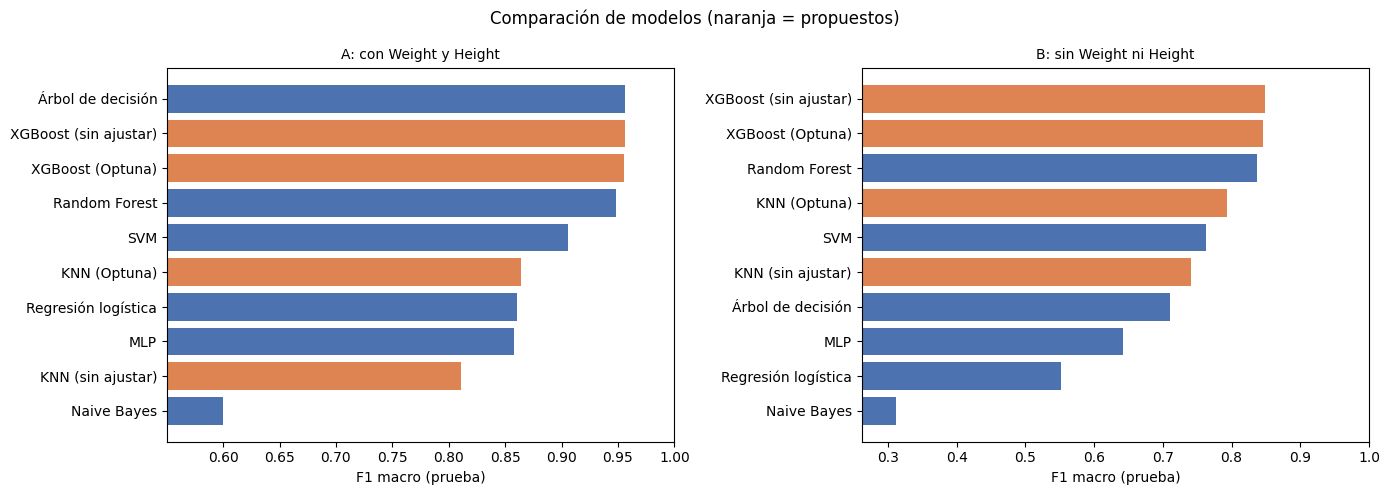

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=False)
for ax, esc in zip(axes, [ESC_A, ESC_B]):
    t = tabla_final[tabla_final["Escenario"] == esc].sort_values("F1 macro (prueba)")
    colores = ["#dd8452" if o == "Propuesto" else "#4c72b0" for o in t["Origen"]]
    ax.barh(t["Modelo"], t["F1 macro (prueba)"], color=colores)
    ax.set_title(esc, fontsize=10); ax.set_xlabel("F1 macro (prueba)")
    ax.set_xlim(max(0, t["F1 macro (prueba)"].min() - 0.05), 1.0)
fig.suptitle("Comparación de modelos (naranja = propuestos)")
plt.tight_layout(); plt.show()


A: con Weight y Height -> mejor modelo: Árbol de decisión

                     precision    recall  f1-score   support

Insufficient_Weight       1.00      1.00      1.00        53
      Normal_Weight       0.92      0.98      0.95        57
 Overweight_Level_I       0.94      0.87      0.91        55
Overweight_Level_II       0.93      0.93      0.93        58
     Obesity_Type_I       0.96      0.96      0.96        70
    Obesity_Type_II       0.97      0.97      0.97        60
   Obesity_Type_III       0.98      0.98      0.98        65

           accuracy                           0.96       418
          macro avg       0.96      0.96      0.96       418
       weighted avg       0.96      0.96      0.96       418



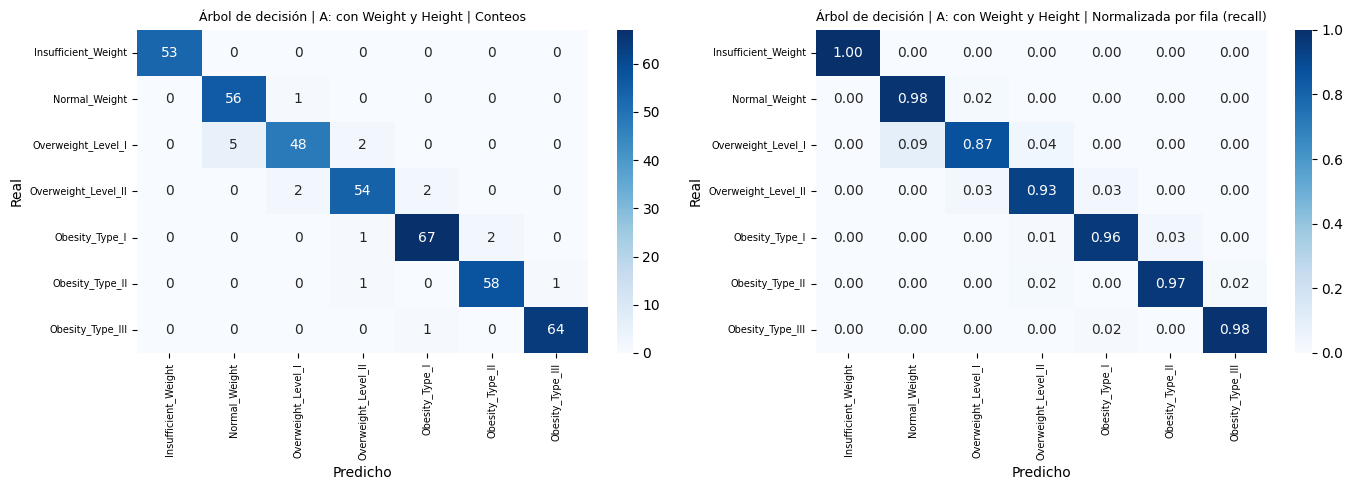


B: sin Weight ni Height -> mejor modelo: XGBoost (sin ajustar)

                     precision    recall  f1-score   support

Insufficient_Weight       0.86      0.94      0.90        53
      Normal_Weight       0.66      0.72      0.69        57
 Overweight_Level_I       0.79      0.82      0.80        55
Overweight_Level_II       0.84      0.71      0.77        58
     Obesity_Type_I       0.85      0.89      0.87        70
    Obesity_Type_II       0.96      0.90      0.93        60
   Obesity_Type_III       1.00      0.97      0.98        65

           accuracy                           0.85       418
          macro avg       0.85      0.85      0.85       418
       weighted avg       0.86      0.85      0.85       418



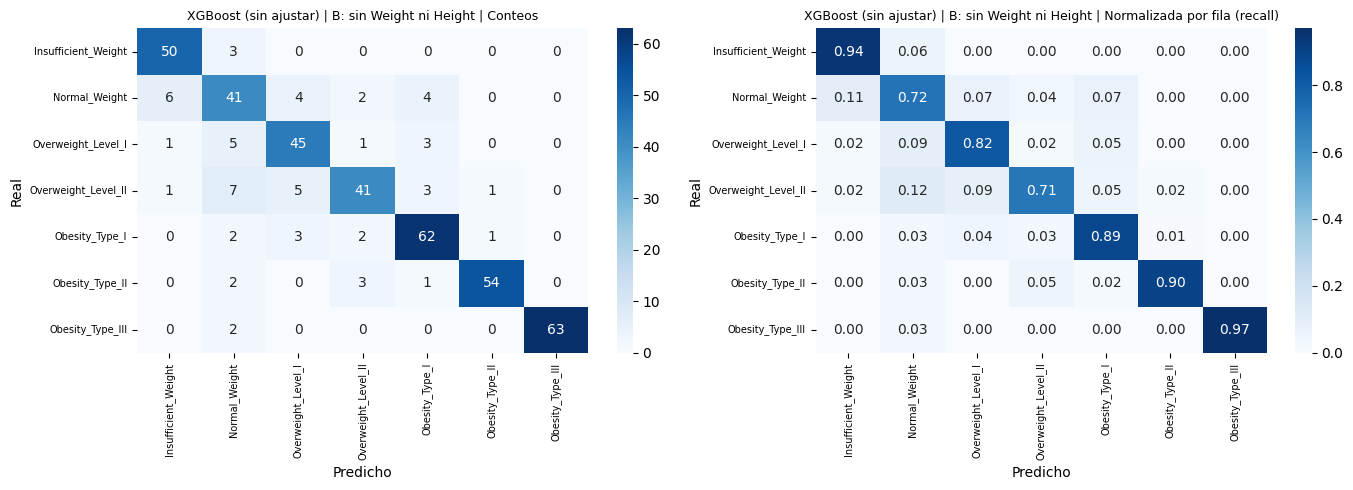


A: con Weight y Height - XGBoost (Optuna)

                     precision    recall  f1-score   support

Insufficient_Weight       0.98      1.00      0.99        53
      Normal_Weight       0.95      0.95      0.95        57
 Overweight_Level_I       0.89      0.89      0.89        55
Overweight_Level_II       0.95      0.90      0.92        58
     Obesity_Type_I       0.93      1.00      0.97        70
    Obesity_Type_II       1.00      0.97      0.98        60
   Obesity_Type_III       1.00      0.98      0.99        65

           accuracy                           0.96       418
          macro avg       0.96      0.96      0.96       418
       weighted avg       0.96      0.96      0.96       418


B: sin Weight ni Height - XGBoost (Optuna)

                     precision    recall  f1-score   support

Insufficient_Weight       0.88      0.92      0.90        53
      Normal_Weight       0.64      0.72      0.68        57
 Overweight_Level_I       0.78      0.84      0.81   

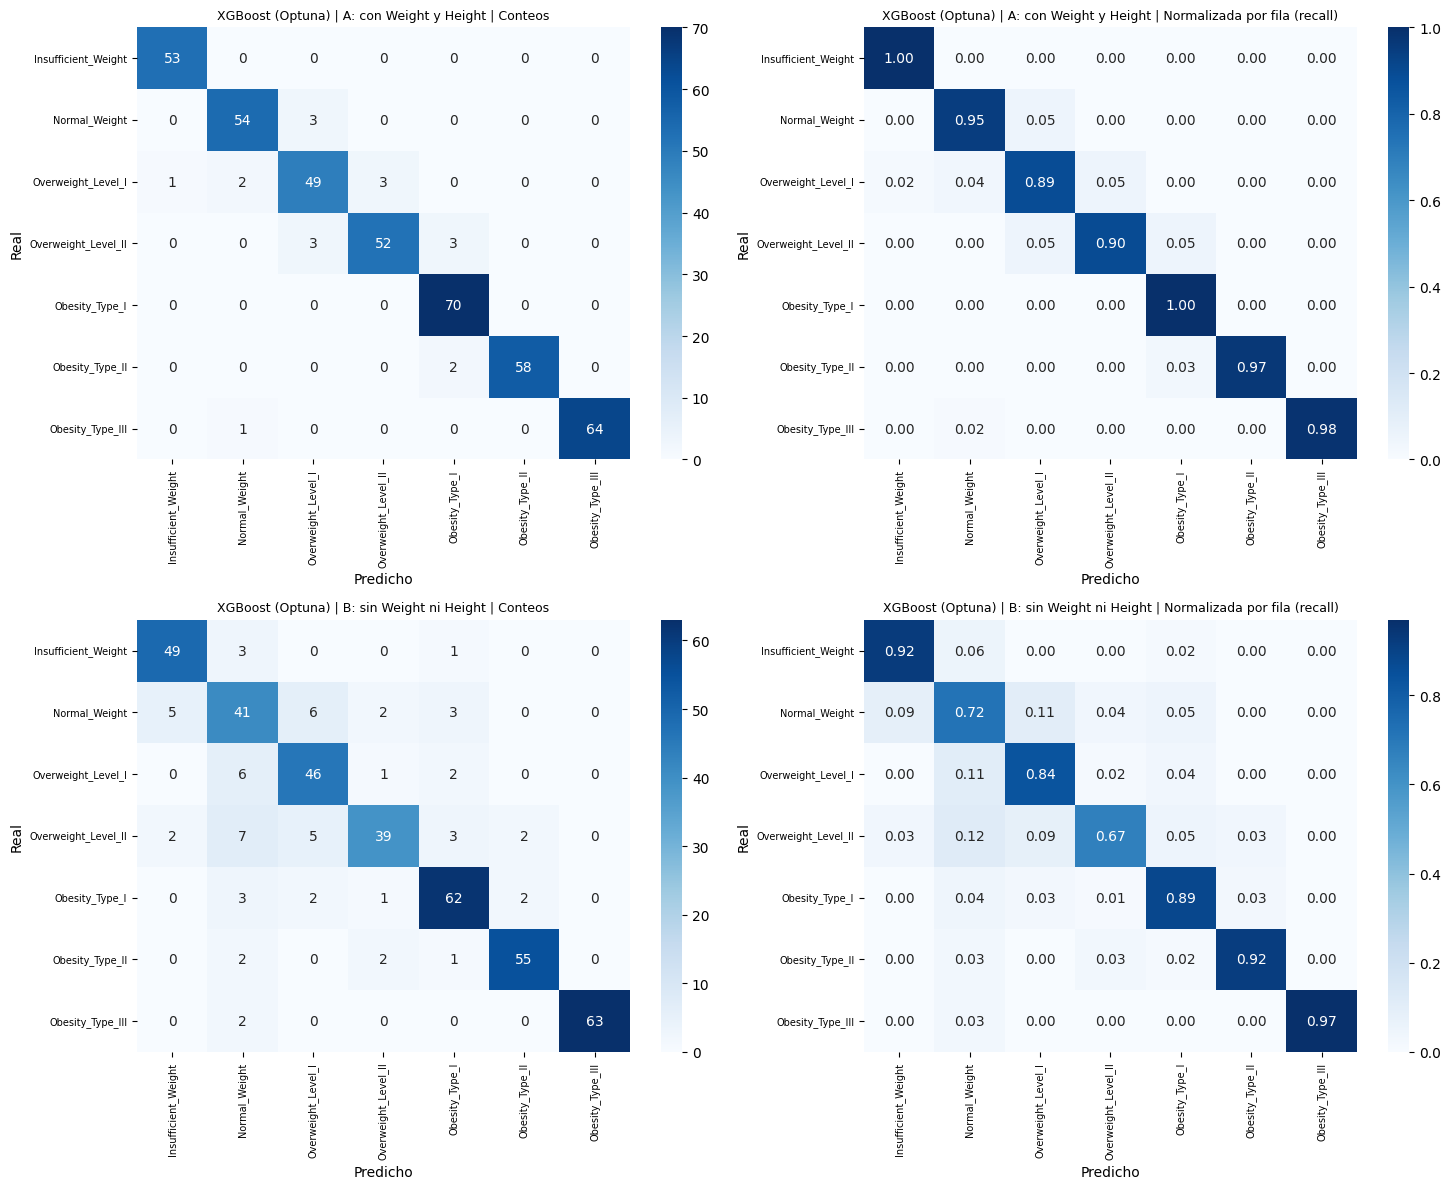

In [ ]:
for esc in [ESC_A, ESC_B]:
    t = tabla_final[tabla_final["Escenario"] == esc].sort_values("F1 macro (prueba)", ascending=False)
    mejor = t.iloc[0]["Modelo"]
    print(f"\n{esc} -> mejor modelo: {mejor}\n")
    print(classification_report(y_test, predicciones[(esc, mejor)], target_names=CLASES, zero_division=0))

    cm = confusion_matrix(y_test, predicciones[(esc, mejor)])
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for ax, M, tt, fmt in [(axes[0], cm, "Conteos", "d"), (axes[1], cm_norm, "Normalizada por fila (recall)", ".2f")]:
        sns.heatmap(M, annot=True, fmt=fmt, cmap="Blues", xticklabels=CLASES, yticklabels=CLASES, ax=ax)
        ax.set_title(f"{mejor} | {esc} | {tt}", fontsize=9); ax.set_xlabel("Predicho"); ax.set_ylabel("Real")
        ax.tick_params(axis="both", labelsize=7)
    plt.tight_layout(); plt.show()


# Matriz de confusión de XGBoost (Optuna) en ambos escenarios
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
for fila, esc in enumerate([ESC_A, ESC_B]):
    pred_xgb = predicciones[(esc, "XGBoost (Optuna)")]
    cm = confusion_matrix(y_test, pred_xgb)
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    for col, (M, titulo, fmt) in enumerate([(cm, "Conteos", "d"),
                                            (cm_norm, "Normalizada por fila (recall)", ".2f")]):
        sns.heatmap(M, annot=True, fmt=fmt, cmap="Blues", xticklabels=CLASES, yticklabels=CLASES,
                    ax=axes[fila, col])
        axes[fila, col].set_title(f"XGBoost (Optuna) | {esc} | {titulo}", fontsize=9)
        axes[fila, col].set_xlabel("Predicho"); axes[fila, col].set_ylabel("Real")
        axes[fila, col].tick_params(axis="both", labelsize=7)
    print(f"\n{esc} - XGBoost (Optuna)\n")
    print(classification_report(y_test, pred_xgb, target_names=CLASES, zero_division=0))
plt.tight_layout(); plt.show()

**Interpretación (escribir con sus palabras):** ¿qué modelo gana en cada escenario y por cuánto? ¿la diferencia es relevante o está dentro del ruido? ¿los errores ocurren entre clases vecinas (mire la columna "% errores a clase vecina")? ¿superan los modelos propuestos a los de los autores?

**Ojo con la validez:** como gran parte de los datos es sintético (SMOTE interpola entre registros reales), el conjunto de prueba contiene casi-copias de datos de entrenamiento, así que las métricas pueden estar infladas. Esto debe mencionarse en la discusión y en la parte ética y social (calidad y representatividad de los datos, sesgo de una muestra de encuesta web, uso de ML para clasificar el peso de las personas).

---

## Pendientes (fuera de este cuaderno)

- Confirmar en los artículos originales qué métodos usaron los autores.
- Reporte: estructura pedida, con redacción propia y la discusión ética y social.